# Phase 1 · Lesson 3: Pandas for ML
**ML Engineer Journey · Benson M. Merita**

**Goal:** learn to move cleanly from a messy real-world table to the clean numeric matrix $X$ and vector $y$ that every model expects. Along the way you'll see that `groupby` is linear algebra in disguise.

You already know Pandas from data analysis. This lesson isn't a Pandas tour. It covers the **ML-specific habits**: inspecting dtypes and missingness, building features with `groupby`/`transform`/`merge`, avoiding the dummy-variable trap, and handing off to NumPy and scikit-learn without breaking row alignment.

| Section | What you get |
|---|---|
| 1 · Intuition | The "feature table" mindset |
| 2 · The math | `groupby` = one-hot matrix $G$; group means = least squares; the dummy trap |
| 3 · From scratch | Group means with NumPy (`np.unique` + `bincount`, then $(G^\top G)^{-1}G^\top y$) |
| 4 · With libraries | Pandas inspection → `groupby` → `transform` → `merge` → `get_dummies` → `X`, `y` |
| 5 · Dataset | Titanic (via seaborn) |
| 6–8 | Exercises, quiz, mistakes & interview questions |
| 🎬 Demo | Survival heatmap, interactive sunburst, missingness chart |

---
## 1 · Intuition

A model can't read a spreadsheet. It needs a **rectangular block of numbers**: one row per *thing you're predicting about* (a passenger, a loan, a customer), one column per *numeric feature*, and a separate column holding the answer.

Real data never arrives like that. It has text categories ("male", "first class"), blanks, several tables that need joining, and information hidden in *groups* ("how did people like this passenger do on average?").

Pandas is the workshop where you do that shaping. In practice, an ML engineer's code is roughly:

> **raw tables → (Pandas) → feature table → (NumPy) → X, y → (scikit-learn) → model**

Most bugs in real ML projects happen in the first arrow: misaligned rows, leaked information, categories encoded wrongly. That's why this lesson focuses on doing it carefully.

**Real ML engineering connection:** the "feature engineering" step you'll formalise in Phase 2, and the feature stores used by ML platform teams, are this same work done at scale.

---
## 2 · The math

**A DataFrame is a labelled matrix.** Rows are indexed samples, and columns are named features of possibly different types. Converting it to numbers means choosing an encoding for every non-numeric column.

**One-hot encoding as a matrix.** For a categorical column with $k$ levels (e.g. class ∈ {First, Second, Third}), define the **indicator matrix**
$$G \in \{0,1\}^{n\times k}, \qquad G_{ij} = \mathbb{1}[\text{row } i \text{ is in group } j]$$
Each row has exactly one 1, so $G\mathbf{1}_k = \mathbf{1}_n$.

**`groupby` is matrix algebra:**
$$\underbrace{G^\top \mathbf{1}_n}_{\text{counts } n_j}, \qquad \underbrace{G^\top y}_{\text{group sums}}, \qquad G^\top G = \operatorname{diag}(n_1,\dots,n_k)$$
$$\text{group means} = (G^\top G)^{-1} G^\top y$$
That last expression is the **normal-equation solution from Lesson 1** with $X = G$. So:

> **Group means are least-squares regression on one-hot features with no intercept.** A regression on a single categorical feature just predicts its group average.

**The dummy-variable trap.** Add an intercept column: $\tilde{X} = [\mathbf{1}_n \mid G]$. Because $\mathbf{1}_n = G\mathbf{1}_k$, the first column is the sum of the others, so $\tilde{X}$ is **rank-deficient** and $\tilde{X}^\top\tilde{X}$ is singular. That's the `LinAlgError` from Lesson 2. The fix is to **drop one level** (`drop_first=True`). The dropped level becomes the baseline, and the other coefficients become *differences from that baseline*.

**Group-wise standardisation is broadcasting:** $z_i = (x_i - \mu_{g(i)})/\sigma_{g(i)}$, where $g(i)$ is row $i$'s group. In Pandas, `groupby(...).transform(...)` returns a vector of length $n$ (one value per row, aligned to the original index) rather than one value per group. That's exactly $G\mu$.

---
## 5 · Practice dataset
**Titanic passengers** (seaborn's copy of the classic dataset; also on Kaggle)
- **891 passengers**, 15 columns: survival, class, sex, age, fare, siblings/spouses aboard (`sibsp`), parents/children aboard (`parch`), port embarked, deck, and more.
- **Task (used in later lessons):** binary classification. Predict `survived` from the passenger's details.
- **Why it's good for Pandas practice:** real missing values (age 20%, deck 77%), text categories, redundant columns that leak the answer, and strong group effects.
- **Load:** `seaborn.load_dataset("titanic")`. It downloads once from GitHub and is cached afterwards.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
pd.set_option("display.width", 120)
np.set_printoptions(precision=3, suppress=True)

df = sns.load_dataset("titanic")
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


---
## 3 · Code from scratch (NumPy only): `groupby` without Pandas
### 3.1 Survival rate by class, the counting way

In [2]:
cls = df["class"].astype(str).to_numpy()          # plain NumPy array of strings
y = df["survived"].to_numpy().astype(float)

levels, codes = np.unique(cls, return_inverse=True)   # levels sorted; codes[i] = group index of row i
counts = np.bincount(codes)                           # n_j
sums = np.bincount(codes, weights=y)                  # sum of y in group j
print("levels:", levels)
print("counts:", counts)
print("survival rate:", sums / counts)

levels: ['First' 'Second' 'Third']
counts: [216 184 491]
survival rate: [0.63  0.473 0.242]


*`np.unique(..., return_inverse=True)` turns text labels into integer codes. That's **label encoding**, and it's how every library stores categories internally. `bincount` with weights is a vectorised "sum per group".*

### 3.2 The same numbers as linear algebra: build $G$ and solve the normal equations

In [3]:
n, k = len(codes), len(levels)
G = np.zeros((n, k))
G[np.arange(n), codes] = 1                           # one-hot via fancy indexing: one 1 per row

print("every row sums to 1:", np.all(G.sum(axis=1) == 1))
print("G^T G (diagonal of counts):\n", G.T @ G)
means_ls = np.linalg.solve(G.T @ G, G.T @ y)         # (G^T G)^{-1} G^T y
print("least-squares coefficients:", means_ls)
print("equal to group means?", np.allclose(means_ls, sums / counts))

every row sums to 1: True
G^T G (diagonal of counts):
 [[216.   0.   0.]
 [  0. 184.   0.]
 [  0.   0. 491.]]
least-squares coefficients: [0.63  0.473 0.242]
equal to group means? True


*Same answer from two routes. A linear regression on one categorical feature learns nothing more than the group averages. Keep that in mind when a model's coefficients look "surprising".*

### 3.3 The dummy-variable trap, made visible

In [4]:
X_trap = np.c_[np.ones(n), G]                        # intercept + ALL k dummies
print("columns:", X_trap.shape[1], "| rank:", np.linalg.matrix_rank(X_trap))
print("condition number of X^T X:", f"{np.linalg.cond(X_trap.T @ X_trap):.2e}")

X_ok = np.c_[np.ones(n), G[:, 1:]]                    # drop the first level (baseline = First class)
w = np.linalg.solve(X_ok.T @ X_ok, X_ok.T @ y)
print("intercept (First-class rate):          ", round(w[0], 3))
print("Second minus First, Third minus First: ", w[1:].round(3))

columns: 4 | rank: 3
condition number of X^T X: 3.79e+16
intercept (First-class rate):           0.63
Second minus First, Third minus First:  [-0.157 -0.387]


*With all $k$ dummies plus an intercept, the rank is $k$, not $k+1$, and the condition number is astronomical. Drop one level and everything is well-posed. Each coefficient now reads as "how much this class differs from First class". This is the same idea as a reference category in your statistics courses.*

---
## 4 · The professional way: Pandas, step by step
### 4.1 Inspect before you touch anything

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [6]:
missing = df.isna().mean().sort_values(ascending=False)
print("share missing per column:\n", missing[missing > 0].round(3))
print("\nduplicate rows:", df.duplicated().sum())

share missing per column:
 deck           0.772
age            0.199
embarked       0.002
embark_town    0.002
dtype: float64

duplicate rows: 107


*Three ML red flags already:*
- *`deck` is **77% missing**, so it's probably unusable as-is.*
- *`alive` is just `survived` written as yes/no, and `who`/`adult_male` are derived from age and sex. **`alive` is target leakage**: a model given it scores 100% and learns nothing. Always ask, "Would I know this column at prediction time?"*
- *`class`/`pclass` and `embarked`/`embark_town` are duplicates in different formats.*

*Some duplicate rows are real (passengers with identical recorded details), so don't drop them blindly.*

### 4.2 Selecting and filtering: and the error you'll make weekly

In [7]:
df["Age"]          # column names are case-sensitive: it's 'age'

KeyError: 'Age'

*`KeyError: 'Age'`. When you get a KeyError, print `df.columns.tolist()` and compare carefully.*

In [8]:
women_first = df.loc[(df["sex"] == "female") & (df["class"] == "First"), ["age", "fare", "survived"]]
print(women_first.shape, "| survival rate:", women_first["survived"].mean().round(3))

(94, 3) | survival rate: 0.968


*Use `.loc[row_mask, column_list]` with `&` / `|` and parentheses around each condition. Python's `and`/`or` raise an error on Series. A boolean mask in Pandas is the same mask you used in NumPy in Lesson 1.*

### 4.3 `groupby`: aggregate (one row per group) vs transform (one value per row)

In [9]:
by_class = df.groupby("class", observed=True)["survived"].agg(["mean", "count"])
print(by_class.round(3))
print("matches the NumPy version:", np.allclose(by_class["mean"].to_numpy(), sums / counts))

print("\nSurvival by class and sex:")
print(df.pivot_table(index="class", columns="sex", values="survived", aggfunc="mean", observed=True).round(2))

         mean  count
class               
First   0.630    216
Second  0.473    184
Third   0.242    491
matches the NumPy version: True

Survival by class and sex:
sex     female  male
class               
First     0.97  0.37
Second    0.92  0.16
Third     0.50  0.14


In [10]:
# transform: broadcast a group statistic back to every row -> a FEATURE
df["fare_vs_class_median"] = df["fare"] / df.groupby("class", observed=True)["fare"].transform("median")
df["family_size"] = df["sibsp"] + df["parch"] + 1
df[["class", "fare", "fare_vs_class_median", "family_size"]].head()

,class,fare,fare_vs_class_median,family_size
0,Third,7.2500,0.900621,2
1,First,71.2833,1.182389,2
2,Third,7.9250,0.984472,1
3,First,53.1000,0.880780,2
4,Third,8.0500,1.000000,1


*`transform` returns a Series with the same index as `df`, which is the $G\mu$ broadcast from the math section. "Fare relative to others in the same class" is often more informative than raw fare. ⚠️ In a real project you compute such statistics on the **training set only** and then map them onto the test set, otherwise it's leakage (Phase 3).*

### 4.4 `merge`: joining a lookup table

In [11]:
ports = pd.DataFrame({
    "embarked": ["S", "C", "Q"],
    "port_name": ["Southampton", "Cherbourg", "Queenstown"],
    "port_country": ["England", "France", "Ireland"],
})
before = len(df)
df = df.merge(ports, on="embarked", how="left", validate="many_to_one")
print("rows before:", before, "| after:", len(df), "| unmatched (missing embarked):", df["port_name"].isna().sum())

rows before: 891 | after: 891 | unmatched (missing embarked): 2


*Two habits worth keeping: **always check the row count after a merge** (a duplicate key in the lookup table silently multiplies rows), and use `validate="many_to_one"` so Pandas raises an error if the lookup isn't unique.*

### 4.5 Handling missing values (simple first; Phase 2 goes deeper)

In [12]:
df["age_missing"] = df["age"].isna().astype(int)                       # keep the fact that it was missing
df["age"] = df["age"].fillna(df.groupby(["class", "sex"], observed=True)["age"].transform("median"))
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
print("age still missing:", df["age"].isna().sum(), "| embarked still missing:", df["embarked"].isna().sum())
print("survival rate, age known vs missing:", df.groupby("age_missing")["survived"].mean().round(3).to_dict())

age still missing: 0 | embarked still missing: 0
survival rate, age known vs missing: {0: 0.406, 1: 0.294}


*Missingness can carry information. Here passengers with unknown ages survived less often, so the `age_missing` flag is a useful feature in its own right. Filling with **group** medians (class × sex) is better than one global median.*

### 4.6 From DataFrame to `X`, `y`: encoding and handoff

In [13]:
features = ["pclass", "sex", "age", "age_missing", "fare", "fare_vs_class_median", "family_size", "embarked"]
X_df = pd.get_dummies(df[features], columns=["sex", "embarked"], drop_first=True, dtype=float)
y_s = df["survived"]

print("X shape:", X_df.shape)
print("columns:", X_df.columns.tolist())
print("all numeric:", all(np.issubdtype(t, np.number) for t in X_df.dtypes))
print("no missing:", X_df.isna().sum().sum() == 0)
print("index aligned with y:", X_df.index.equals(y_s.index))

X, y = X_df.to_numpy(), y_s.to_numpy()          # the arrays scikit-learn will consume
print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype)

X shape: (891, 9)
columns: ['pclass', 'age', 'age_missing', 'fare', 'fare_vs_class_median', 'family_size', 'sex_male', 'embarked_Q', 'embarked_S']
all numeric: True
no missing: True
index aligned with y: True
X: (891, 9) float64 | y: (891,) int64


*`drop_first=True` avoids the dummy trap from 3.3. `sex_male` = 1 means male, and female is the baseline. Leakage columns (`alive`, `who`, `adult_male`) and the 77%-missing `deck` were left out on purpose.*

### 4.7 Sanity check: scikit-learn agrees with your least-squares group means

In [14]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

enc = OneHotEncoder(drop="first", sparse_output=False)
G_sk = enc.fit_transform(df[["class"]].astype(str))
lr = LinearRegression().fit(G_sk, df["survived"])
print("encoder categories:", enc.categories_[0].tolist())
print("intercept:", round(lr.intercept_, 3), "| coefs:", lr.coef_.round(3))
print("matches section 3.3:", np.allclose([lr.intercept_, *lr.coef_], w))

encoder categories: ['First', 'Second', 'Third']
intercept: 0.63 | coefs: [-0.157 -0.387]
matches section 3.3: True


*In a production pipeline you'd use `OneHotEncoder` rather than `get_dummies`. It **remembers** the categories it saw during `fit`, so new data with a missing or unseen category still gets the same columns. `get_dummies` re-derives the columns each time, which can silently misalign train and test. You'll wire this into a `Pipeline` in Phase 5.*

| Your NumPy | Pandas / scikit-learn |
|---|---|
| `np.unique(..., return_inverse=True)` | `.astype("category").cat.codes` / `LabelEncoder` |
| `bincount(codes, weights=y) / counts` | `df.groupby(col)[y].mean()` |
| `G` via fancy indexing | `pd.get_dummies` / `OneHotEncoder` |
| `G @ group_means` | `groupby(...).transform("mean")` |
| `G[:, 1:]` | `drop_first=True` / `drop="first"` |

---
## 🎬 Demo visuals for your post
### Demo A: survival heatmap + missingness (`assets/titanic_overview.png`)

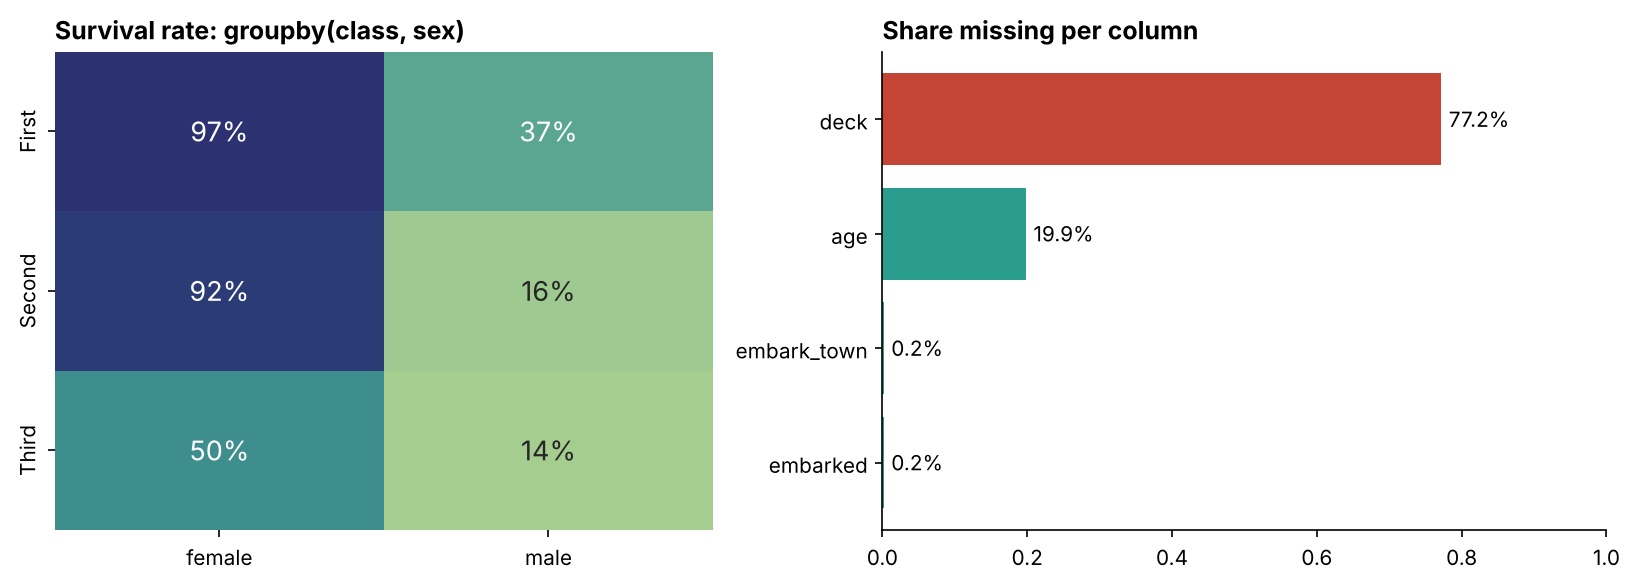

In [15]:
import matplotlib.pyplot as plt
raw = sns.load_dataset("titanic")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=150, gridspec_kw={"width_ratios": [1, 1.1]})
pt = raw.pivot_table(index="class", columns="sex", values="survived", aggfunc="mean", observed=True)
sns.heatmap(pt, annot=True, fmt=".0%", cmap="crest", cbar=False, ax=axes[0], annot_kws={"size": 13})
axes[0].set_title("Survival rate: groupby(class, sex)", loc="left", fontweight="bold")
axes[0].set_xlabel(""); axes[0].set_ylabel("")
m = raw.isna().mean().sort_values()
m = m[m > 0]
axes[1].barh(m.index, m.values, color=["#2a9d8f" if v < .5 else "#c44536" for v in m.values])
for i, v in enumerate(m.values):
    axes[1].text(v + .01, i, f"{v:.1%}", va="center")
axes[1].set_xlim(0, 1); axes[1].set_title("Share missing per column", loc="left", fontweight="bold")
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("assets/titanic_overview.png", bbox_inches="tight"); plt.show()

### Demo B: interactive sunburst. Click a ring to drill in (`assets/titanic_sunburst.html`)

In [16]:
import plotly.express as px
sb = raw.assign(outcome=raw["survived"].map({1: "survived", 0: "died"}), cls=raw["class"].astype(str))
sb = sb.groupby(["cls", "sex", "outcome"], observed=True).size().reset_index(name="passengers")
figs = px.sunburst(sb, path=["cls", "sex", "outcome"], values="passengers", color="outcome",
                   color_discrete_map={"survived": "#2a9d8f", "died": "#c44536", "(?)": "#e9ecef"},
                   title="Titanic: class -> sex -> outcome (click to drill in)")
figs.write_html("assets/titanic_sunburst.html", include_plotlyjs="cdn")
print("Saved assets/titanic_sunburst.html")

Saved assets/titanic_sunburst.html


---
## 6 · Exercises (answers hidden; send your code when ready)
Work in `lesson03_exercises.ipynb`, starting from a fresh `sns.load_dataset("titanic")`.

1. **(Easy) Inspect:** Write `profile(df)` that returns a DataFrame with one row per column: dtype, % missing, number of unique values, and an example value. Run it on Titanic.
2. **(Easy) Groupby:** What's the survival rate by `embarked` *and* `class`? Which combination is highest, and how many passengers is it based on? (Small groups mislead, so always report the count.)
3. **(Medium) Title feature:** seaborn's version has no names. Download Kaggle's `train.csv` (or use `fetch_openml("titanic", version=1, as_frame=True)`), extract the title ("Mr", "Mrs", "Miss", "Master", …) from the name column (`Name` in Kaggle, `name` in OpenML) with `.str.extract`, group rare titles into "Rare", and show survival by title. Why might title help fill missing ages?
4. **(Medium–Hard) Group means from scratch, two keys:** Reproduce `df.groupby(["class", "sex"])["survived"].mean()` using only NumPy. Combine the two codes into one integer key, then use `bincount`. Verify with `np.allclose`.
5. **(Challenge) Leak hunt:** Fit `LinearRegression` on `X` from section 4.6 with and without an added `alive` column (encoded 0/1). Compare the training R² (`.score`). Explain in 3–4 sentences why the second model is useless in practice even though it scores better. Then name one *subtler* leak in the original 15 columns.

## 7 · Mini-quiz
1. What is the difference between `groupby(...).agg("mean")` and `groupby(...).transform("mean")` in output shape, and when do you use each?
2. Why is $[\mathbf{1} \mid G]$ rank-deficient? What does `drop_first=True` change about how you interpret the coefficients?
3. After `df.merge(lookup, on="key")` your DataFrame went from 891 to 903 rows. What happened, and how do you prevent it?
4. Why prefer `OneHotEncoder` over `pd.get_dummies` inside a model that will predict on new data?

## 8 · Common mistakes & interview questions
**Common mistakes**
- **Target leakage:** keeping columns that encode the answer (`alive`) or are only known *after* the outcome.
- **Merges that multiply rows:** always check `len()` before and after, and use `validate=`.
- **Dummy trap:** all $k$ dummies plus an intercept in a linear model.
- **Train/test category mismatch with `get_dummies`:** different columns in each set.
- **Filling missing values with whole-dataset statistics** before splitting (leakage again).
- **`and`/`or` instead of `&`/`|`**, or missing parentheses in masks.
- **Losing row alignment:** resetting or sorting X without doing the same to y, or converting to NumPy too early.
- **Chained assignment** like `df[df.age > 60]["fare"] = 0`: it doesn't modify `df`. Use `df.loc[mask, "fare"] = 0`.

**Interview questions**
1. Walk me through how you'd prepare a raw CSV for a model.
2. What is target leakage? Give an example from a project.
3. How do you handle a categorical feature with 1,000 levels? (Preview: frequency or target encoding, hashing, embeddings.)
4. What is the dummy-variable trap, and does it matter for tree-based models?
5. How do you treat missing values, and when is "missing" itself a feature?
6. `merge` vs `concat` vs `join`: when do you use each?

---
### ✅ Lesson 3 checklist
- [ ] Notebook runs top to bottom
- [ ] Exercises 1–5 attempted
- [ ] Quiz answered
- [ ] Post: heatmap/sunburst + write-up (see `SOCIAL_PACK.md`)
- [ ] `git commit -m "Lesson 3: Pandas for ML, groupby as linear algebra, X/y handoff"` + `git push`

**Next lesson:** Visualisation for EDA: Matplotlib's object model, Seaborn for distributions and relationships, and charts that make a model's story clear.